In [ ]:
# CRISP-DM: Telco Customer Churn Prediction

from google.colab import files

uploaded = files.upload()



Saving Telecom Custmer Data Churn.csv to Telecom Custmer Data Churn.csv


In [4]:
#Load data and inspect it:
import pandas as pd

file_name = "Telecom Custmer Data Churn.csv"
df = pd.read_csv(file_name)

df.head()

df.shape
df.info()
df.isnull().sum().sort_values(ascending=False)
df.duplicated().sum()
df["Churn"].value_counts()
df["Churn"].value_counts(normalize=True).mul(100).round(2)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,proportion
Churn,
No,73.46
Yes,26.54


In [5]:
#CRISP-DM Phase 3: Data Preparation.

import pandas as pd

file_name = "Telecom Custmer Data Churn.csv"
raw_df = pd.read_csv(file_name)

df = raw_df.copy()
df.head()

#Clean the data:

df.columns = df.columns.str.strip()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

df.isnull().sum().sort_values(ascending=False)

#Remove invalid rows and the identifier:
df = df.dropna(subset=["TotalCharges"]).copy()
df = df.drop(columns=["customerID"])

#Convert the target:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})


In [6]:
#split the data
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5625, 19)
(1407, 19)


In [8]:
# Data Preparation by encoding categorical columns and scaling numerical columns.

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

#Pre- processing pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])



X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared testing shape:", X_test_prepared.shape)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Prepared training shape: (5625, 45)
Prepared testing shape: (1407, 45)


In [9]:
#CRISP-DM Phase 4: Modeling

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_prepared, y_train)

y_pred = logistic_model.predict(X_test_prepared)
y_prob = logistic_model.predict_proba(X_test_prepared)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8038379530916845
ROC-AUC: 0.8359290473207676

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



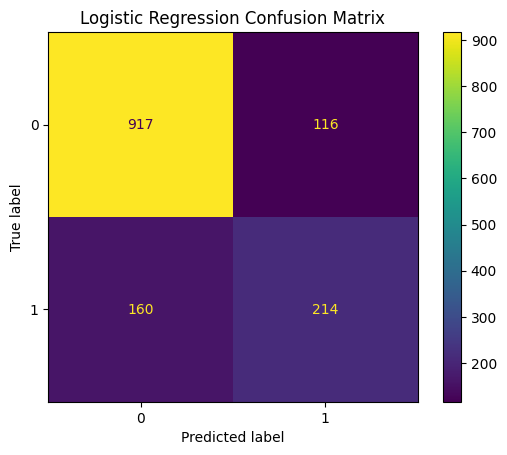

In [10]:
# Generating confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [11]:
# Random Forest:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_prepared, y_train)

rf_pred = random_forest_model.predict(X_test_prepared)
rf_prob = random_forest_model.predict_proba(X_test_prepared)[:, 1]

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Accuracy: 0.7903340440653873
ROC-AUC: 0.8127941047051577

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.49      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [12]:
# Gradient Boosting

from sklearn.ensemble import GradientBoostingClassifier

# Convert sparse matrices to dense arrays if necessary
X_train_dense = (
    X_train_prepared.toarray()
    if hasattr(X_train_prepared, "toarray")
    else X_train_prepared
)

X_test_dense = (
    X_test_prepared.toarray()
    if hasattr(X_test_prepared, "toarray")
    else X_test_prepared
)

gradient_model = GradientBoostingClassifier(
    random_state=42
)

gradient_model.fit(X_train_dense, y_train)

gb_pred = gradient_model.predict(X_test_dense)
gb_prob = gradient_model.predict_proba(X_test_dense)[:, 1]

print("Accuracy:", accuracy_score(y_test, gb_pred))
print("ROC-AUC:", roc_auc_score(y_test, gb_prob))
print("\nClassification Report:")
print(classification_report(y_test, gb_pred))

Accuracy: 0.7960199004975125
ROC-AUC: 0.8385989615418462

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



In [13]:
# Model comparison
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, gb_prob)
    ],
    "Churn Recall": [
        classification_report(y_test, y_pred, output_dict=True)["1"]["recall"],
        classification_report(y_test, rf_pred, output_dict=True)["1"]["recall"],
        classification_report(y_test, gb_pred, output_dict=True)["1"]["recall"]
    ],
    "Churn F1": [
        classification_report(y_test, y_pred, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, rf_pred, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, gb_pred, output_dict=True)["1"]["f1-score"]
    ]
})

model_comparison.round(3)

,Model,Accuracy,ROC-AUC,Churn Recall,Churn F1
0,Logistic Regression,0.804,0.836,0.572,0.608
1,Random Forest,0.790,0.813,0.495,0.556
2,Gradient Boosting,0.796,0.839,0.529,0.580


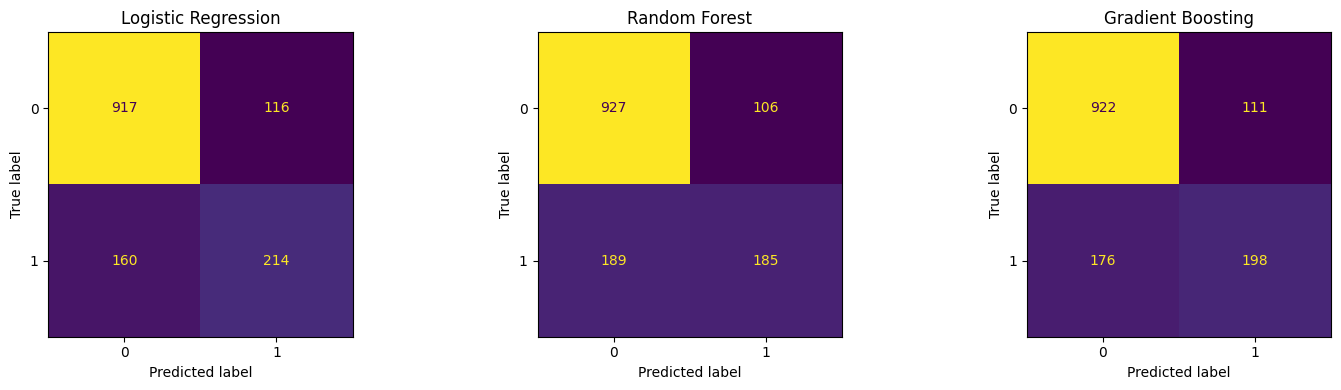

In [14]:
# Evaluation

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, ax=axes[0], colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, ax=axes[1], colorbar=False
)
axes[1].set_title("Random Forest")

ConfusionMatrixDisplay.from_predictions(
    y_test, gb_pred, ax=axes[2], colorbar=False
)
axes[2].set_title("Gradient Boosting")

plt.tight_layout()
plt.show()

In [15]:
# Now we will tune the Logistic Regression decision threshold.
#The default threshold is 0.50. Lowering it means the model will classify more customers as “likely to churn,” which may increase recall but also create more false positives.


import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.40, 0.50, 0.60]

threshold_results = []

for threshold in thresholds:
    threshold_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_pred),
        "Recall": recall_score(y_test, threshold_pred),
        "F1-score": f1_score(y_test, threshold_pred)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)

,Threshold,Precision,Recall,F1-score
0,0.3,0.511,0.759,0.611
1,0.4,0.579,0.684,0.627
2,0.5,0.648,0.572,0.608
3,0.6,0.679,0.385,0.491


Final threshold: 0.4
Accuracy: 0.7839374555792467

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.82      0.85      1033
           1       0.58      0.68      0.63       374

    accuracy                           0.78      1407
   macro avg       0.73      0.75      0.74      1407
weighted avg       0.80      0.78      0.79      1407



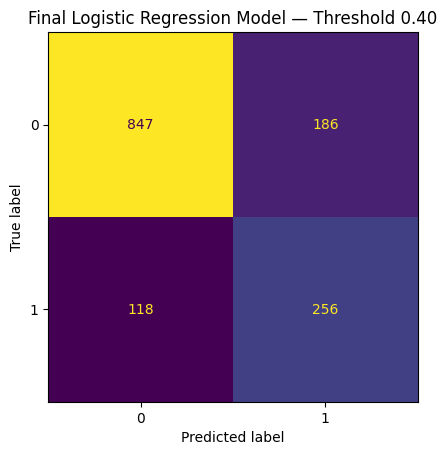

In [16]:
#finliazed the threshold = 0.40

final_threshold = 0.40

y_pred_final = (y_prob >= final_threshold).astype(int)

print("Final threshold:", final_threshold)
print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    colorbar=False
)

plt.title("Final Logistic Regression Model — Threshold 0.40")
plt.show()

In [20]:
# Model saving code

import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    preprocessor,
    "models/telco_preprocessor.joblib"
)

joblib.dump(
    logistic_model,
    "models/telco_churn_logistic_model.joblib"
)

joblib.dump(
    {"threshold": 0.40},
    "models/deployment_config.joblib"
)

print("Files saved successfully.")

os.listdir("models")

Files saved successfully.


['telco_preprocessor.joblib',
 'deployment_config.joblib',
 'telco_churn_logistic_model.joblib']